<a href="https://colab.research.google.com/github/hridayrjain/AI-Lab/blob/main/1BM24CS119_Week9_FOL_Resolution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Number of premises (press Enter for demo): 

KB in CNF:
  (1) Likes(John,x1) | ~Food(x1)
  (2) Food(Apple)
  (3) Food(Vegetables)
  (4) Food(y3) | Killed(x2) | ~Eats(x2,y3)
  (5) Eats(Anil,Peanuts)
  (6) Alive(Anil)
  (7) Eats(Harry,x4) | ~Eats(Anil,x4)
  (8) ~Alive(x5) | ~Killed(x5)
  (9) Alive(x6) | Killed(x6)
Negated goal:
  (10) ~Likes(John,Peanuts)

Resolution steps:
  (11) Resolve (10) and (1) {x1/Peanuts} -> ~Food(Peanuts)
  (12) Resolve (11) and (4) {y3/Peanuts} -> Killed(x2) | ~Eats(x2,Peanuts)
  (13) Resolve (12) and (5) {x2/Anil} -> Killed(Anil)
  (16) Resolve (13) and (8) {x5/Anil} -> ~Alive(Anil)
  (21) Resolve (16) and (6) {} -> {} (empty clause)

Query PROVED: Likes(John,Peanuts)


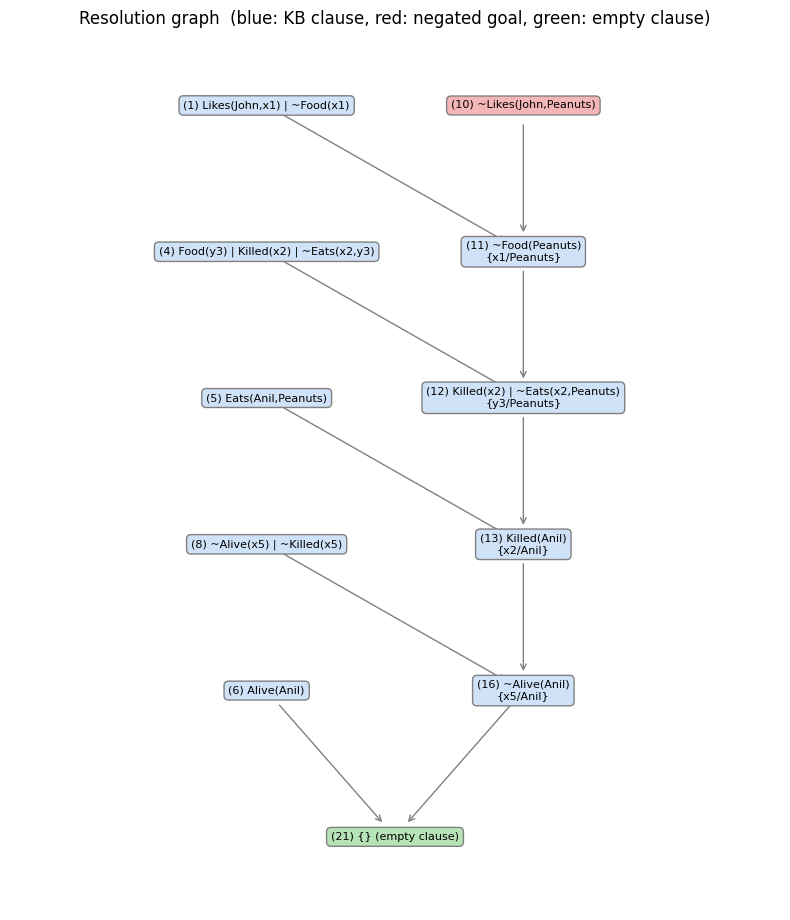

In [1]:
"""FOL resolution theorem prover with proof-graph plot.
Syntax: Predicates/constants Capitalised, variables lowercase.  ~  &  |  ->  <->
        forall x (...)   exists y (...)   (a quantifier binds the next unary/parenthesised formula)"""
import re, itertools
import matplotlib.pyplot as plt

# ---------------- parser: text -> formula tuples ----------------
def parse(s):
    toks, pos = re.findall(r'<->|->|[()~&|,]|\w+', s), [0]
    peek = lambda: toks[pos[0]] if pos[0] < len(toks) else None
    def eat(): pos[0] += 1; return toks[pos[0] - 1]
    def term():
        n = eat()
        if peek() != '(': return n
        eat(); args = [term()]
        while peek() == ',': eat(); args.append(term())
        eat(); return (n, *args)
    def unary():
        t = eat()
        if t == '~': return ('not', unary())
        if t == '(': f = iff(); eat(); return f
        if t in ('forall', 'exists'): v = eat(); return ('all' if t == 'forall' else 'ex', v, unary())
        pos[0] -= 1; a = term(); return a if isinstance(a, tuple) else (a,)
    def binary(sub, op, name):
        f = sub()
        while peek() == op: eat(); f = (name, f, sub())
        return f
    def imp():
        f = binary(lambda: binary(unary, '&', 'and'), '|', 'or')
        if peek() == '->': eat(); return ('imp', f, imp())
        return f
    iff = lambda: binary(imp, '<->', 'iff')
    return iff()

# ---------------- CNF conversion ----------------
cnt = itertools.count(1)
def nnf(f, neg=False):                       # remove -> <->, push ~ inwards
    op = f[0]
    if op == 'imp': return nnf(('or', ('not', f[1]), f[2]), neg)
    if op == 'iff': return nnf(('and', ('imp', f[1], f[2]), ('imp', f[2], f[1])), neg)
    if op == 'not': return nnf(f[1], not neg)
    if op in ('and', 'or'): return ({'and': 'or', 'or': 'and'}[op] if neg else op, nnf(f[1], neg), nnf(f[2], neg))
    if op in ('all', 'ex'): return ({'all': 'ex', 'ex': 'all'}[op] if neg else op, f[1], nnf(f[2], neg))
    return ('not', f) if neg else f

def sub(t, env): return env.get(t, t) if isinstance(t, str) else (t[0], *[sub(a, env) for a in t[1:]])

def skolem(f, env, univ):                    # standardise variables + Skolemise + drop quantifiers
    op = f[0]
    if op == 'all': v = f'{f[1]}{next(cnt)}'; return skolem(f[2], {**env, f[1]: v}, univ + [v])
    if op == 'ex': k = f'Sk{next(cnt)}'; return skolem(f[2], {**env, f[1]: (k, *univ) if univ else k}, univ)
    if op in ('and', 'or'): return (op, skolem(f[1], env, univ), skolem(f[2], env, univ))
    return ('not', sub(f[1], env)) if op == 'not' else sub(f, env)

def cnf(f):                                  # distribute | over &  -> list of clauses (frozensets of literals)
    if f[0] == 'and': return cnf(f[1]) + cnf(f[2])
    if f[0] == 'or': return [a | b for a in cnf(f[1]) for b in cnf(f[2])]
    return [frozenset([(False, f[1]) if f[0] == 'not' else (True, f)])]

def to_cnf(f): return [c for c in cnf(skolem(nnf(f), {}, [])) if not any((not s, a) in c for s, a in c)]

# ---------------- unification ----------------
isvar = lambda t: isinstance(t, str) and t[0].islower()
def walk(t, s):
    while isvar(t) and t in s: t = s[t]
    return t
def occurs(v, t, s):
    t = walk(t, s); return t == v or (isinstance(t, tuple) and any(occurs(v, a, s) for a in t[1:]))
def unify(a, b, s):
    if s is None: return None
    a, b = walk(a, s), walk(b, s)
    if a == b: return s
    if isvar(a): return None if occurs(a, b, s) else {**s, a: b}
    if isvar(b): return unify(b, a, s)
    if isinstance(a, tuple) and isinstance(b, tuple) and a[0] == b[0] and len(a) == len(b):
        for x, y in zip(a[1:], b[1:]): s = unify(x, y, s)
        return s
def apply(t, s):
    t = walk(t, s); return t if isinstance(t, str) else (t[0], *[apply(a, s) for a in t[1:]])
def vs(t): return ({t} if isvar(t) else set()) if isinstance(t, str) else set().union(*map(vs, t[1:]))

def rename(c, k):                            # standardise a clause apart
    r = lambda t: (re.sub(r'_\d+$', '', t) + f'_{k}' if isvar(t) else t) if isinstance(t, str) else (t[0], *map(r, t[1:]))
    return frozenset((s, r(a)) for s, a in c)

# ---------------- printing ----------------
ts = lambda t: t if isinstance(t, str) else (f"{t[0]}({','.join(map(ts, t[1:]))})" if len(t) > 1 else t[0])
ls = lambda l: ('' if l[0] else '~') + ts(l[1])
cs = lambda c: re.sub(r'(?<=\w)_\d+', '', ' | '.join(sorted(map(ls, c)))) or '{} (empty clause)'

# ---------------- resolution (set-of-support, BFS) ----------------
def resolve(kb, goal, limit=3000):
    nodes = [(c, None, '') for c in kb + goal]               # (clause, parents, substitution text)
    seen, queue, k = {frozenset(map(ls, c)) for c in kb + goal}, list(range(len(kb), len(nodes))), 0
    while queue and len(nodes) < limit:
        a = queue.pop(0); A = nodes[a][0]
        for b in range(len(nodes)):
            k += 1; B = rename(nodes[b][0], k)
            for la in A:
                for lb in B:
                    s = unify(la[1], lb[1], {}) if la[0] != lb[0] else None
                    if s is None: continue
                    new = frozenset((x, apply(t, s)) for x, t in (A - {la}) | (B - {lb}))
                    key = frozenset(map(ls, new))
                    if key in seen or any((not x, t) in new for x, t in new): continue
                    seen.add(key)
                    sb = ', '.join(f'{v}/{ts(apply(v, s))}' for v in sorted(set().union(*[vs(t) for _, t in A | B])) if apply(v, s) != v)
                    nodes.append((new, (a, b), re.sub(r'(?<=\w)_\d+', '', '{' + sb + '}')))
                    if not new: return nodes
                    queue.append(len(nodes) - 1)

def ancestors(nodes, i, out):
    if i not in out:
        out.add(i)
        for p in nodes[i][1] or (): ancestors(nodes, p, out)
    return out

# ---------------- resolution graph ----------------
def plot(nodes, anc, n_kb, path='resolution_graph.png'):
    lvl = {}
    for i in sorted(anc): lvl[i] = 0 if not nodes[i][1] else 1 + max(lvl[p] for p in nodes[i][1])
    for i in anc:                                            # draw each KB/goal clause just above its first use
        if not nodes[i][1]: lvl[i] = min(lvl[j] for j in anc if i in (nodes[j][1] or ())) - 1
    rows = {l: [i for i in sorted(anc) if lvl[i] == l] for l in set(lvl.values())}
    order = lambda r: (lambda lf, dv: lf[::2] + dv + lf[1::2])([i for i in r if not nodes[i][1]], [i for i in r if nodes[i][1]])
    pos = {i: ((n + 1) / (len(r) + 1), -l) for l, r in rows.items() for n, i in enumerate(order(r))}
    fig, ax = plt.subplots(figsize=(max(8, 3.2 * max(map(len, rows.values()))), 1.3 * len(rows) + 1.5))
    for i in anc:
        for p in nodes[i][1] or ():
            ax.annotate('', xy=pos[i], xytext=pos[p], arrowprops=dict(arrowstyle='->', color='gray', shrinkA=14, shrinkB=14))
    for i, (x, y) in pos.items():
        c, par, sb = nodes[i]
        col = '#b7e4b7' if not c else '#f4b6b6' if (par is None and i >= n_kb) else '#cfe2f7'
        ax.text(x, y, f'({i + 1}) {cs(c)}' + (f'\n{sb}' if par and sb != '{}' else ''), ha='center', va='center',
                fontsize=8, bbox=dict(boxstyle='round,pad=0.4', fc=col, ec='gray'))
    ax.set_xlim(0, 1); ax.set_ylim(-len(rows) + 0.5, 0.5); ax.axis('off')
    ax.set_title('Resolution graph  (blue: KB clause, red: negated goal, green: empty clause)')
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

# ---------------- main ----------------
DEMO = ["forall x (Food(x) -> Likes(John,x))", "Food(Apple) & Food(Vegetables)",
        "forall x forall y ((Eats(x,y) & ~Killed(x)) -> Food(y))", "Eats(Anil,Peanuts) & Alive(Anil)",
        "forall x (Eats(Anil,x) -> Eats(Harry,x))", "forall x (Alive(x) -> ~Killed(x))", "forall x (~Killed(x) -> Alive(x))"]
GOAL = "Likes(John,Peanuts)"

if __name__ == '__main__':
    n = input('Number of premises (press Enter for demo): ').strip()
    kb, goal = ([input(f'Premise {i + 1}: ') for i in range(int(n))], input('Goal: ')) if n else (DEMO, GOAL)
    clauses = [c for s in kb for c in to_cnf(parse(s))]
    negated = to_cnf(('not', parse(goal)))
    print('\nKB in CNF:')
    for i, c in enumerate(clauses): print(f'  ({i + 1}) {cs(c)}')
    print('Negated goal:')
    for i, c in enumerate(negated): print(f'  ({len(clauses) + i + 1}) {cs(c)}')
    nodes = resolve(clauses, negated)
    if nodes and not nodes[-1][0]:
        anc = ancestors(nodes, len(nodes) - 1, set())
        print('\nResolution steps:')
        for i in sorted(anc):
            if nodes[i][1]: print(f'  ({i + 1}) Resolve ({nodes[i][1][0] + 1}) and ({nodes[i][1][1] + 1}) {nodes[i][2]} -> {cs(nodes[i][0])}')
        print(f'\nQuery PROVED: {goal}')
        plot(nodes, anc, len(clauses))
    else:
        print(f'\nQuery NOT proved: {goal}')